# YAFS Deep Analysis

Notebook ini memecah analisis menjadi 5 bagian sesuai ketentuan:
1) **Network definition**
2) **Application definition**
3) **User / Workload definition**
4) **Result analysis (penempatan Fog vs Cloud)**
5) **Performance metrics**: latency, response time, throughput, CPU/RAM utilization, reliability

> Catatan: Notebook ini mengasumsikan struktur folder standar: `data/` dan `results/`. Jika nama file/letak berbeda, sesuaikan path pada sel konfigurasi.

In [1]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

DATA_DIR    = Path('data')
RESULTS_DIR = Path('results')
ALGOS = ['CN','ILP','GA', 'FSPCN']  # tambahkan 'FSPCN' jika ada

def read_json(p: Path):
    if p.exists():
        return json.loads(p.read_text())
    return {}

def read_csv_any(p: Path):
    try:
        return pd.read_csv(p)
    except:
        return pd.read_csv(p, sep=';')

def pick_result_file(folder: Path, algo: str, link: bool=False):
    patt = f"results_{algo}_*{'_link' if link else ''}.csv"
    cands = list(folder.glob(patt))
    if not cands:
        return None
    cands_10000 = [p for p in cands if '10000' in p.stem]
    pool = cands_10000 if cands_10000 else cands
    pool.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    return pool[0]


## 1) Network definition

Jumlah node: 101, perkiraan m: 3
Jumlah link: 301
Rata-rata derajat: 5.96039603960396
Rata-rata clustering: 0.14728730161063178
Rata-rata shortest path (komponen penuh): 2.5855445544554456


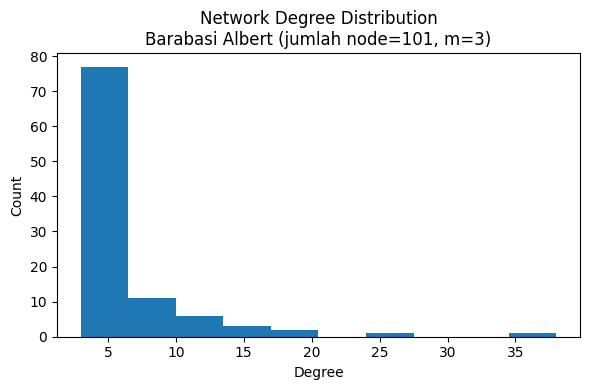

In [2]:
net = read_json(DATA_DIR/'networkDefinition.json')

def build_graph(net: dict) -> nx.Graph:
    G = nx.Graph()
    for d in net.get('entity', []):
        G.add_node(int(d['id']), **d)
    for e in net.get('link', net.get('links', [])):
        if 's' in e and 'd' in e:
            s, t = int(e['s']), int(e['d'])
            latency = float(e.get('latency', e.get('PR', 1.0)))
            bw = float(e.get('bw', e.get('BW', 1.0)))
            weight = latency / max(bw, 1e-9)
            G.add_edge(s, t, latency=latency, bw=bw, w=weight)
    return G

def infer_ba_params(net: dict):
    n = len(net.get('entity', []))
    links = net.get('link', net.get('links', []))
    m = None
    if n > 0:
        E = len(links)
        avg_deg = 2*E / n
        m = int(round(avg_deg / 2))
    # metadata (opsional) net['model']['m']
    if isinstance(net.get('model'), dict) and 'm' in net['model']:
        try:
            m = int(net['model']['m'])
        except:
            pass
    return n, m

G = build_graph(net)
n_nodes, m_param = infer_ba_params(net)
degrees = [deg for _, deg in G.degree()]

print(f'Jumlah node: {n_nodes}, perkiraan m: {m_param}')
print('Jumlah link:', G.number_of_edges())
print('Rata-rata derajat:', np.mean(degrees) if degrees else np.nan)
print('Rata-rata clustering:', nx.average_clustering(G) if G.number_of_nodes()>1 else np.nan)
if G.number_of_nodes()>1:
    if nx.is_connected(G):
        print('Rata-rata shortest path (komponen penuh):', nx.average_shortest_path_length(G))
    else:
        comp = max(nx.connected_components(G), key=len)
        sub = G.subgraph(comp).copy()
        print('Rata-rata shortest path (komponen terbesar):', nx.average_shortest_path_length(sub))

# Histogram degree
plt.figure(figsize=(6,4))
plt.hist(degrees, bins=min(20, max(5, int(np.sqrt(len(degrees))))) if degrees else 5)
plt.xlabel('Degree'); plt.ylabel('Count')
plt.title(f'Network Degree Distribution\nBarabasi Albert (jumlah node={n_nodes}, m={m_param})')
plt.tight_layout(); plt.show()


CLOUD: 1, CFG: 10, FOG: 80, FG: 10


/var/folders/wv/xmd6tbzd5ng0cxlyp0swk29m0000gn/T/ipykernel_7210/2635278250.py:135: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


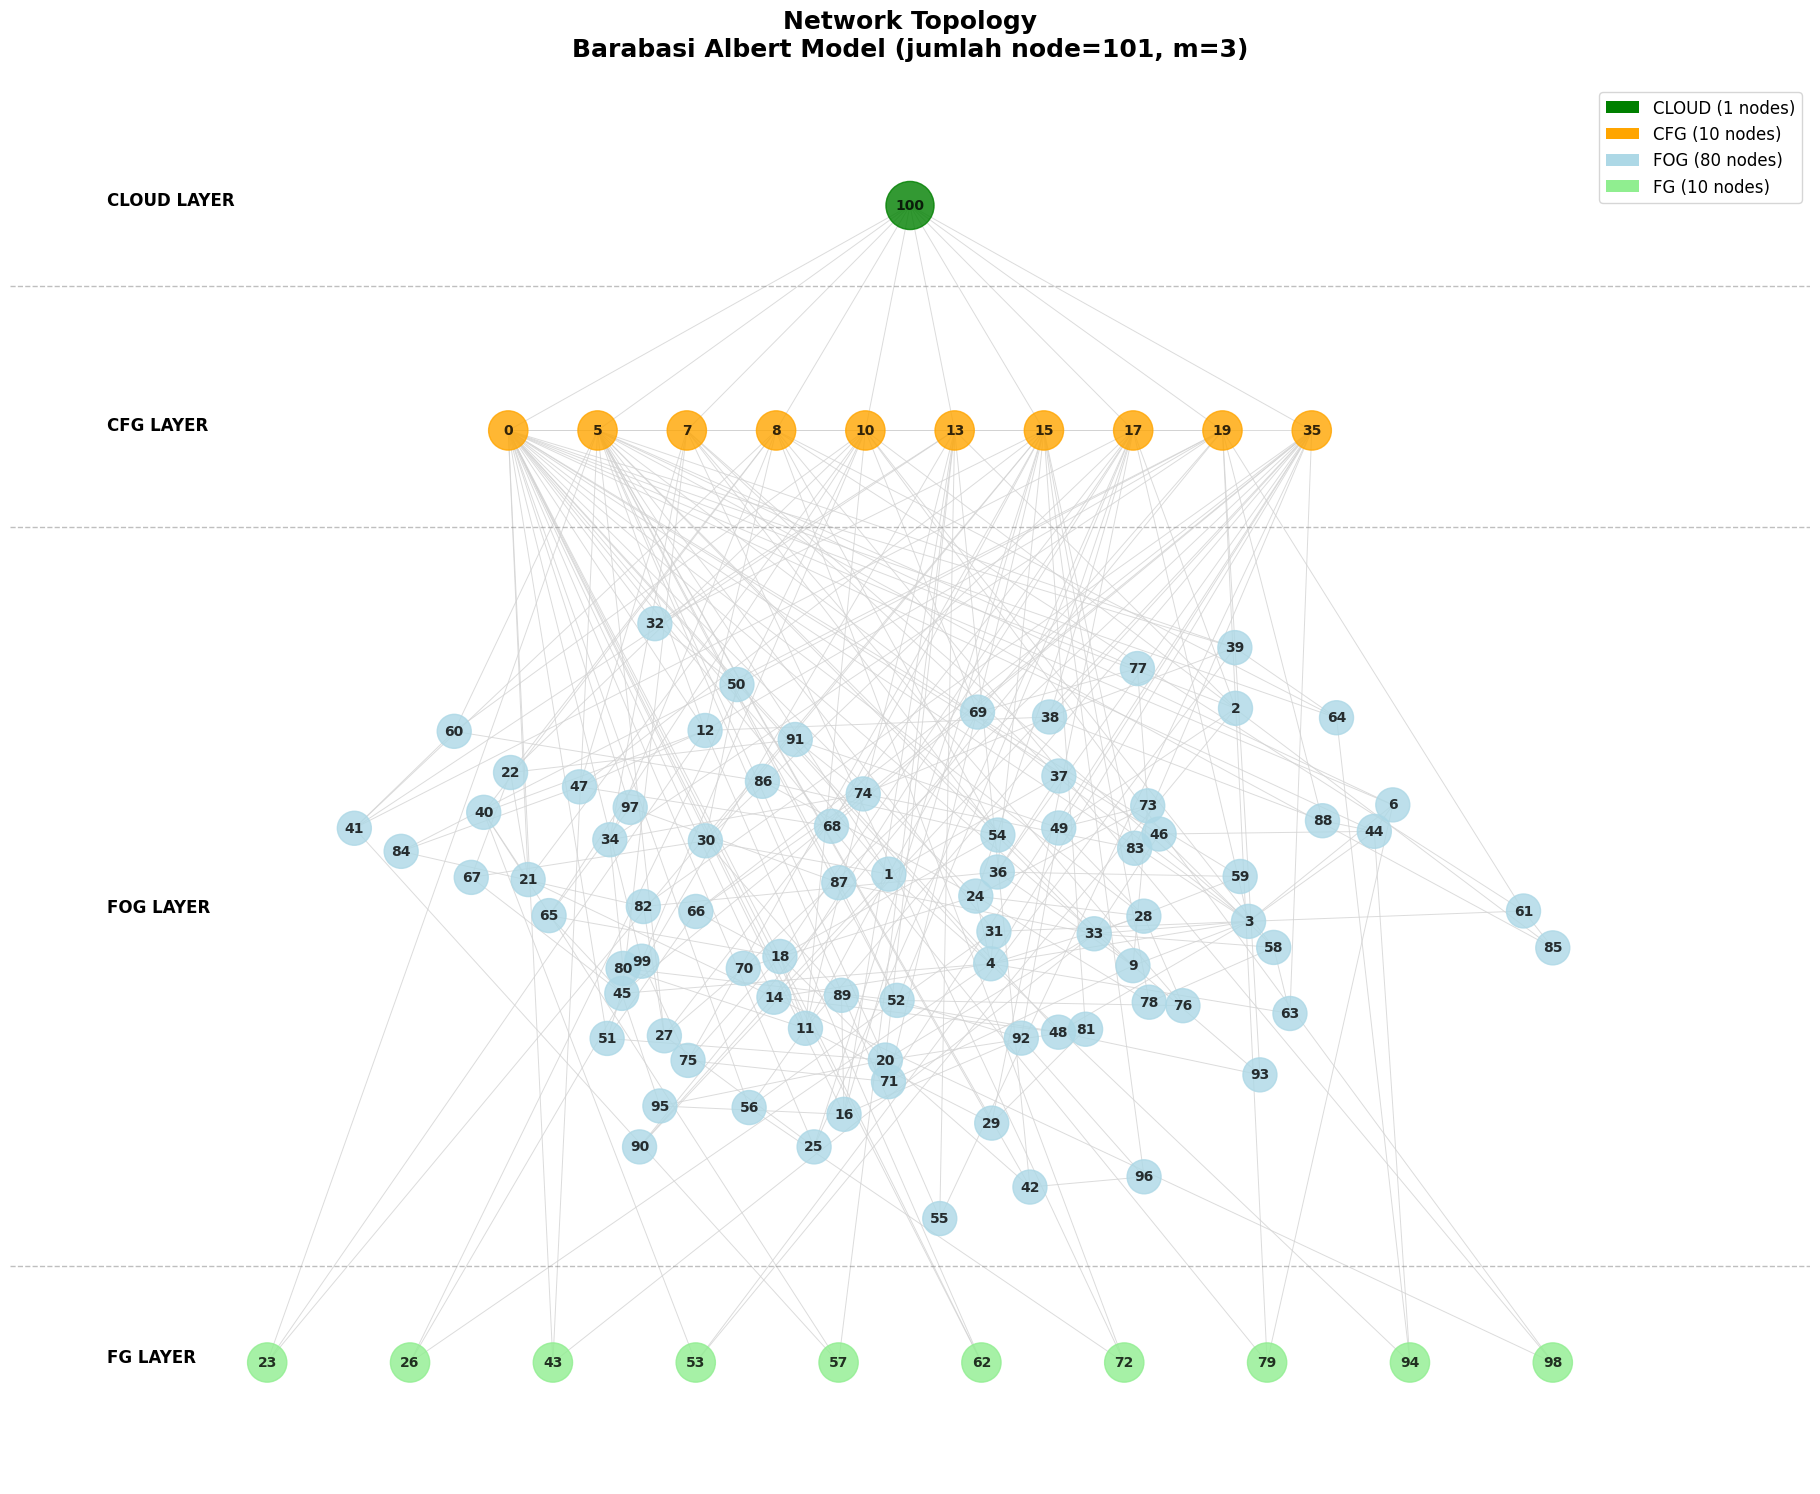


=== CLOUD CONNECTIONS ===
Cloud node 100 terhubung dengan 10 nodes: [0, 35, 5, 7, 8, 10, 13, 15, 17, 19]

=== NODE DISTRIBUTION ===
CLOUD: 1 nodes
CFG: 10 nodes
FOG: 80 nodes
FG: 10 nodes
Total: 101 nodes


In [8]:
# Visualisasi graf NetworkX
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

plt.figure(figsize=(18, 14))

# Definisikan warna untuk setiap tipe node
color_map = {
    'CLOUD': 'green',
    'CFG': 'orange', 
    'FOG': 'lightblue',
    'FG': 'lightgreen'
}

# Kategorisasi node berdasarkan type
cloud_nodes = [node for node in G.nodes() if G.nodes[node].get('type') == 'CLOUD']
cfg_nodes = [node for node in G.nodes() if G.nodes[node].get('type') == 'CFG']
fog_nodes = [node for node in G.nodes() if G.nodes[node].get('type') == 'FOG']
fg_nodes = [node for node in G.nodes() if G.nodes[node].get('type') == 'FG']

print(f"CLOUD: {len(cloud_nodes)}, CFG: {len(cfg_nodes)}, FOG: {len(fog_nodes)}, FG: {len(fg_nodes)}")

# Manual positioning untuk layout berlapis
pos = {}

# Layer 1: CLOUD
y_cloud = 3.0
for i, node in enumerate(cloud_nodes):
    pos[node] = (0, y_cloud)

# Layer 2: CFG (EDIT DISINI - spacing diperkecil dan dicentering)
y_cfg = 2.3
cfg_spacing = 2.5 / max(1, len(cfg_nodes) - 1) if len(cfg_nodes) > 1 else 0  # Diperkecil dari 5.0 ke 2.5
for i, node in enumerate(cfg_nodes):
    x_cfg = -1.25 + i * cfg_spacing if len(cfg_nodes) > 1 else 0  # Range diperkecil dari -3.0 ke -1.25
    pos[node] = (x_cfg, y_cfg)

# Layer 3: FOG
if fog_nodes:
    # Buat subgraph hanya untuk FOG nodes
    fog_subgraph = G.subgraph(fog_nodes)
    # Spring layout khusus untuk FOG dengan area terbatas
    fog_pos = nx.spring_layout(fog_subgraph, k=0.8, iterations=100, seed=42)
    
    # Scale dan shift FOG positions ke area tengah
    y_fog = 0.8
    fog_width = 4.0  # lebar area FOG
    fog_height = 2.0  # tinggi area FOG
    
    for node in fog_nodes:
        # Scale dari [-1,1] ke area yang diinginkan
        x_scaled = fog_pos[node][0] * fog_width/2
        y_scaled = fog_pos[node][1] * fog_height/2 + y_fog
        pos[node] = (x_scaled, y_scaled)

# Layer 4: FG
y_fg = -0.6
fg_spacing = 4.0 / max(1, len(fg_nodes) - 1) if len(fg_nodes) > 1 else 0
for i, node in enumerate(fg_nodes):
    x_fg = -2.0 + i * fg_spacing if len(fg_nodes) > 1 else 0
    pos[node] = (x_fg, y_fg)

# Buat list warna dan ukuran berdasarkan hierarki
node_colors = []
node_sizes = []

for node in G.nodes():
    node_type = G.nodes[node].get('type', 'FOG')
    node_colors.append(color_map.get(node_type, 'gray'))
    
    if node_type == 'CLOUD':
        size = 1200
    elif node_type == 'CFG':
        size = 800
    elif node_type == 'FOG':
        size = 600
    else:  # FG
        size = 800
    node_sizes.append(size)

# Draw graf dengan layout manual
nx.draw(G, pos, 
        node_color=node_colors, 
        node_size=node_sizes,
        with_labels=True, 
        font_size=10,
        font_weight='bold',
        font_color='black',
        edge_color='lightgray',
        width=0.7,
        alpha=0.8)

# Tambahkan garis horizontal untuk memisahkan layer
plt.axhline(y=2.75, color='gray', linestyle='--', alpha=0.5, linewidth=1)
plt.axhline(y=2, color='gray', linestyle='--', alpha=0.5, linewidth=1)
plt.axhline(y=-0.3, color='gray', linestyle='--', alpha=0.5, linewidth=1)

# Tambahkan label layer
plt.text(-2.5, 3.0, 'CLOUD LAYER', fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, 2.3, 'CFG LAYER', fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, 0.8, 'FOG LAYER', fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, -0.6, 'FG LAYER', fontsize=12, fontweight='bold', ha='left')

# Legend diurutkan sesuai hierarki (CLOUD, CFG, FOG, FG)
legend_elements = []
legend_order = ['CLOUD', 'CFG', 'FOG', 'FG']
for node_type in legend_order:
    color = color_map[node_type]
    count = len([n for n in G.nodes() if G.nodes[n].get('type') == node_type])
    legend_elements.append(Patch(facecolor=color, label=f'{node_type} ({count} nodes)'))

plt.legend(handles=legend_elements, loc='upper right', fontsize=12)

# jumlah node
num_nodes = len(net.get("entity", []))

# cari m (kalau ada metadata)
m_value = None
if "model" in net:
    m_value = net["model"].get("m")

# fallback: hitung dari jumlah link
if m_value is None and "link" in net:
    num_links = len(net["link"])
    m_value = round((2*num_links/num_nodes)/2)

# --- gunakan di title ---
plt.title(
    f"Network Topology\nBarabasi Albert Model (jumlah node={num_nodes}, m={m_value})",
    fontsize=18, fontweight="bold", pad=20
)

plt.axis('equal')
plt.tight_layout()
plt.show()

print("\n=== CLOUD CONNECTIONS ===")
if cloud_nodes:
    cloud_node = cloud_nodes[0]
    cloud_neighbors = list(G.neighbors(cloud_node))
    print(f"Cloud node {cloud_node} terhubung dengan {len(cloud_neighbors)} nodes: {cloud_neighbors}")

print("\n=== NODE DISTRIBUTION ===")
print(f"CLOUD: {len(cloud_nodes)} nodes")
print(f"CFG: {len(cfg_nodes)} nodes") 
print(f"FOG: {len(fog_nodes)} nodes")
print(f"FG: {len(fg_nodes)} nodes")
print(f"Total: {len(G.nodes())} nodes")

## 2) Application definition

In [3]:
app = read_json(DATA_DIR/'appDefinition.json')

def build_app_dag(app: dict):
    dag = nx.DiGraph()
    apps = app if isinstance(app, list) else app.get('apps',[app]) if app else []
    for a in apps:
        for m in a.get('message', []):
            src, dst = m.get('src'), m.get('dst')
            if src and dst:
                dag.add_edge(src, dst, name=m.get('name'), instructions=float(m.get('instructions',0)))
    return dag

def critical_path_instructions(dag: nx.DiGraph) -> float:
    if dag.number_of_nodes()==0: return 0.0
    topo = list(nx.topological_sort(dag))
    best = {v:0.0 for v in topo}
    for u in topo:
        for v in dag.successors(u):
            w = float(dag[u][v].get('instructions',0.0))
            best[v] = max(best[v], best[u]+w)
    return max(best.values()) if best else 0.0

dag = build_app_dag(app)
print('Nodes (modules) dalam DAG:', dag.number_of_nodes())
print('Edges (messages) dalam DAG:', dag.number_of_edges())
print('Critical path (sum of instructions):', critical_path_instructions(dag))


Nodes (modules) dalam DAG: 0
Edges (messages) dalam DAG: 0
Critical path (sum of instructions): 0.0


## 3) User / Workload definition

,id_resource,lambda_sum
0,26,225.0
1,43,609.0
2,53,359.0
3,57,3608.0
4,72,773.0
5,79,1173.0
6,94,442.0
7,98,958.0


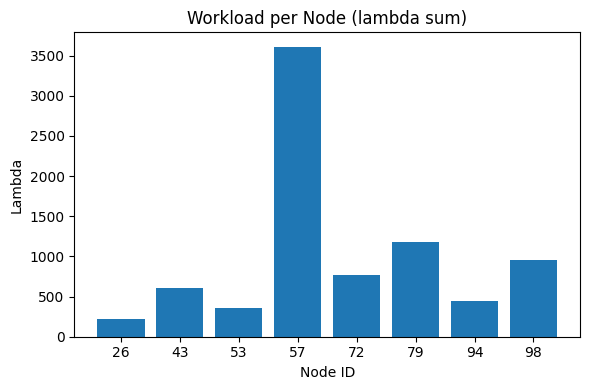

In [4]:
users = read_json(DATA_DIR/'usersDefinition.json')
rows = []
for s in users.get('sources', []):
    rows.append({'id_resource': int(s.get('id_resource', -1)), 'lambda': float(s.get('lambda', 0))})
df_work = pd.DataFrame(rows)
if not df_work.empty:
    df_work = df_work.groupby('id_resource')['lambda'].sum().reset_index(name='lambda_sum')
    display(df_work)
    plt.figure(figsize=(6,4))
    plt.bar(df_work['id_resource'].astype(str), df_work['lambda_sum'])
    plt.title('Workload per Node (lambda sum)')
    plt.xlabel('Node ID'); plt.ylabel('Lambda')
    plt.tight_layout(); plt.show()
else:
    print('usersDefinition.json tidak memiliki sources atau kosong')


## 4) Result analysis (penempatan Fog vs Cloud)

,algorithm,cloud,fog,total
0,CN,77,39,146
1,FSPCN,0,58,61
2,GA,12,23,61
3,ILP,76,22,146


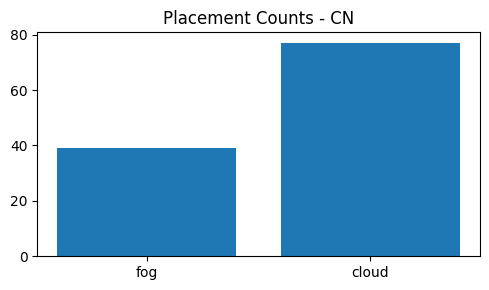

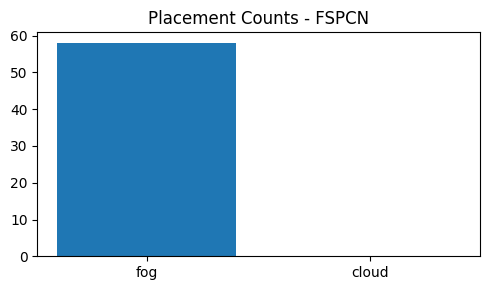

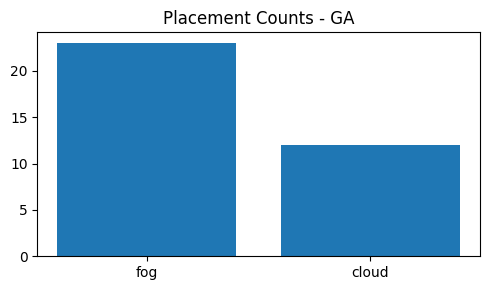

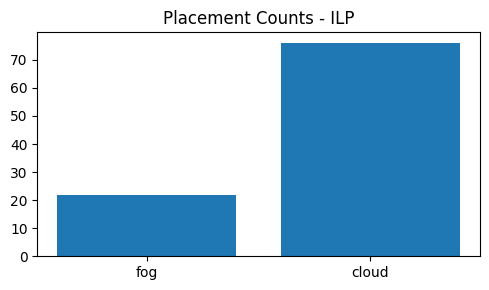

In [5]:
def load_allocations():
    rows = []
    for fn in ['allocDefinitionCN.json','allocDefinitionILP.json','allocDefinitionGA.json','allocDefinitionFSPCN.json']:
        p = DATA_DIR / fn
        if not p.exists():
            continue
        data = read_json(p)
        algo = fn.replace('allocDefinition','').replace('.json','')
        for it in data.get('initialAllocation', []):
            rows.append({'algorithm': algo,
                         'module': it.get('module_name') or it.get('module'),
                         'id_resource': int(it.get('id_resource', -1))})
    return pd.DataFrame(rows)

def fog_cloud_counts(df_alloc: pd.DataFrame, net: dict):
    type_map = {int(d['id']): str(d.get('type','')).upper() for d in net.get('entity', [])}
    res = []
    for alg, g in df_alloc.groupby('algorithm'):
        cloud = sum(1 for _,r in g.iterrows() if type_map.get(r['id_resource'],'') in ('CLOUD','CFG'))
        fog   = sum(1 for _,r in g.iterrows() if type_map.get(r['id_resource'],'')=='FOG')
        res.append({'algorithm': alg, 'cloud': cloud, 'fog': fog, 'total': len(g)})
    return pd.DataFrame(res)

df_alloc = load_allocations()
if not df_alloc.empty:
    df_fc = fog_cloud_counts(df_alloc, net)
    display(df_fc)
    for _, r in df_fc.iterrows():
        plt.figure(figsize=(5,3))
        plt.bar(['fog','cloud'], [r['fog'], r['cloud']])
        plt.title(f"Placement Counts - {r['algorithm']}")
        plt.tight_layout(); plt.show()
else:
    print('Tidak menemukan allocDefinition*.json')


## 5) Performance metrics

In [6]:
def e2e_latency(df: pd.DataFrame):
    if {'time_in','time_out'}.issubset(df.columns):
        return pd.to_numeric(df['time_out'], errors='coerce') - pd.to_numeric(df['time_in'], errors='coerce')
    return pd.Series(dtype=float)

def response_time(df: pd.DataFrame):
    if {'time_emit','time_reception'}.issubset(df.columns):
        return pd.to_numeric(df['time_reception'], errors='coerce') - pd.to_numeric(df['time_emit'], errors='coerce')
    return e2e_latency(df)

def throughput(df: pd.DataFrame):
    if {'time_in','time_out'}.issubset(df.columns):
        t_in  = pd.to_numeric(df['time_in'], errors='coerce')
        t_out = pd.to_numeric(df['time_out'], errors='coerce')
        dur = (t_out.max() - t_in.min())
        completed = (t_out.notna()).sum()
        return float(completed / dur) if pd.notna(dur) and dur>0 else float('nan')
    return float('nan')

def reliability(df: pd.DataFrame):
    emits = df['time_emit'].notna().sum() if 'time_emit' in df.columns else df['time_in'].notna().sum()
    recvs = df['time_reception'].notna().sum() if 'time_reception' in df.columns else df['time_out'].notna().sum()
    return float(recvs / emits) if emits else float('nan')

perf_rows = []
for algo in ALGOS:
    p = pick_result_file(RESULTS_DIR, algo, link=False)
    df = read_csv_any(p) if p else None
    if df is None or df.empty:
        perf_rows.append({'algorithm': algo})
        continue
    lat = e2e_latency(df).dropna()
    resp = response_time(df).dropna()
    thr = throughput(df)
    rel = reliability(df)
    perf_rows.append({
        'algorithm': algo,
        'latency_p50': float(np.nanpercentile(lat,50)) if len(lat) else np.nan,
        'latency_p95': float(np.nanpercentile(lat,95)) if len(lat) else np.nan,
        'response_p50': float(np.nanpercentile(resp,50)) if len(resp) else np.nan,
        'throughput': thr,
        'reliability': rel
    })

df_perf = pd.DataFrame(perf_rows)
display(df_perf)

# 5a) Latency
plt.figure(figsize=(6,4)); plt.bar(df_perf['algorithm'], df_perf['latency_p50']); plt.title('Latency p50'); plt.tight_layout(); plt.show()
plt.figure(figsize=(6,4)); plt.bar(df_perf['algorithm'], df_perf['latency_p95']); plt.title('Latency p95'); plt.tight_layout(); plt.show()

# 5b) Response time
plt.figure(figsize=(6,4)); plt.bar(df_perf['algorithm'], df_perf['response_p50']); plt.title('Response Time p50'); plt.tight_layout(); plt.show()

# 5c) Throughput
plt.figure(figsize=(6,4)); plt.bar(df_perf['algorithm'], df_perf['throughput']); plt.title('Throughput'); plt.tight_layout(); plt.show()

# 5d) Reliability
plt.figure(figsize=(6,4)); plt.bar(df_perf['algorithm'], df_perf['reliability']); plt.title('Reliability'); plt.ylim(0,1.05); plt.tight_layout(); plt.show()


KeyError: 'time_in'

### 5e) Resource utilization (CPU & RAM)

In [ ]:
def device_caps(net: dict):
    MIPS, RAM = {}, {}
    for d in net.get('entity', []):
        did = int(d['id'])
        MIPS[did] = float(d.get('MIPS', d.get('IPT', 0)))
        RAM[did]  = float(d.get('RAM', 0))
    return MIPS, RAM

def msg_instr_map(app: dict):
    instr = {}
    apps = app if isinstance(app, list) else app.get('apps',[app]) if app else []
    for a in apps:
        for m in a.get('message', []):
            instr[m.get('name')] = float(m.get('instructions', 0))
    return instr

def cpu_util(df: pd.DataFrame, MIPS: dict, instr_map: dict):
    if df is None or df.empty or not MIPS or 'message' not in df.columns:
        return {}
    if {'time_in','time_out'}.issubset(df.columns):
        t_in  = pd.to_numeric(df['time_in'], errors='coerce')
        t_out = pd.to_numeric(df['time_out'], errors='coerce')
        dur = (t_out.max() - t_in.min())
    else:
        return {}
    if not pd.notna(dur) or dur<=0: return {}
    dev_col = next((c for c in ('DES.dst','id_resource','dst','device') if c in df.columns), None)
    if dev_col is None: return {}
    tmp = df[[dev_col,'message']].dropna()
    tmp['instr'] = tmp['message'].map(instr_map).fillna(0.0)
    agg = tmp.groupby(dev_col)['instr'].sum()
    util = {}
    for dev,total in agg.items():
        try:
            did = int(dev)
        except:
            continue
        mips = MIPS.get(did, 0.0)
        util[did] = float(total / (mips * dur)) if mips>0 else float('nan')
    return util

def ram_util(df_alloc: pd.DataFrame, RAM: dict, service_ram: dict):
    if df_alloc is None or df_alloc.empty: return {}
    usage = {}
    for _,r in df_alloc.iterrows():
        dev = int(r['id_resource']); mod = str(r['module']) if 'module' in r else str(r.get('module_name'))
        need = float(service_ram.get(mod, 0.0))
        usage[dev] = usage.get(dev, 0.0) + need
    return {dev: (usage[dev]/RAM.get(dev,1.0) if RAM.get(dev,0)>0 else float('nan')) for dev in usage}

MIPS, RAM = device_caps(net)
instr_map = msg_instr_map(app)

# peta RAM per service
service_ram = {}
apps = app if isinstance(app, list) else app.get('apps',[app]) if app else []
for a in apps:
    for mod in a.get('module', []):
        if str(mod.get('type','')).upper() in ('SERVICE','MODULE'):
            service_ram[mod['name']] = float(mod.get('RAM', 0))

for algo in ALGOS:
    p = pick_result_file(RESULTS_DIR, algo, link=False)
    df = read_csv_any(p) if p else None
    cpu_map = cpu_util(df, MIPS, instr_map)
    # filter alloc untuk algo tersebut
    df_alloc_algo = df_alloc[df_alloc['algorithm']==algo] if 'df_alloc' in globals() and not df_alloc.empty else pd.DataFrame()
    ram_map = ram_util(df_alloc_algo, RAM, service_ram)

    def topk(d: dict, k=5):
        items = [(k_,v) for k_,v in d.items() if pd.notna(v) and np.isfinite(v)]
        items.sort(key=lambda x: x[1], reverse=True)
        return items[:k]

    top_cpu = topk(cpu_map, 5)
    top_ram = topk(ram_map, 5)

    if top_cpu:
        x, y = [str(i) for i,_ in top_cpu], [v for _,v in top_cpu]
        plt.figure(figsize=(6,4)); plt.bar(x,y); plt.title(f'CPU Utilization (top-5) - {algo}')
        plt.ylabel('fraction'); plt.tight_layout(); plt.show()

    if top_ram:
        x, y = [str(i) for i,_ in top_ram], [v for _,v in top_ram]
        plt.figure(figsize=(6,4)); plt.bar(x,y); plt.title(f'RAM Utilization (top-5) - {algo}')
        plt.ylabel('fraction'); plt.tight_layout(); plt.show()
